# Bloque C - C6: Efecto de la compresión JPEG

**Objetivo:** evaluar cómo afectan distintos niveles de **compresión JPEG** a las imágenes, a las **características cromáticas** (C4) y a la **identificación de eritrocitos parasitados** con el criterio de color elegido en C5. Es la tarea C6 del anteproyecto ("evaluar el efecto de varios niveles de compresión JPEG sobre las imágenes y las características cromáticas") y una parte de la evaluación final que propone (efecto de la compresión sobre la identificación).

**Por qué importa:** JPEG es una compresión **con pérdida**. Para achicar el archivo, descarta detalles finos (divide la imagen en bloques de 8×8 y elimina las frecuencias altas) y guarda el color con **menos resolución que el brillo** (submuestreo de croma). Justo lo que usamos para detectar parásitos son **manchas chicas y oscuras/violetas**, así que podrían verse afectadas.

**Cómo lo hacemos (solo con train):**
1. Cada imagen de train se **recomprime** con calidades JPEG 95, 85, 75, 50, 25 y 10, y se vuelve a descomprimir.
2. Medimos la **calidad de la imagen** respecto de la original: tamaño del archivo, PSNR, SSIM y diferencia de color dentro de las células (ΔE).
3. Recalculamos las **47 características de color** de cada eritrocito del GT (con `color_features.py`) y medimos cuánto cambian y si siguen separando parasitadas de sanas.
4. Aplicamos el **criterio final de C5** ("la célula tiene al menos una mancha de C3") y medimos sensibilidad, precisión y F1 para cada calidad.

**Todos los parámetros quedan fijos** (referencia de normalización, rangos de color y parámetros de la máscara de C3, ajustados con train en C2-C5): no se reajusta nada para las imágenes comprimidas, igual que pasaría con una imagen nueva. Lo que medimos es **cuánto cambian los resultados** respecto de la imagen original.

> **Ojo:** las imágenes "originales" del dataset **ya son JPEG** (fotos de celular). Lo que evaluamos es el efecto de una **compresión adicional**.

**Test no se usa.**

In [1]:
# BLOQUE C - C6: Efecto de la compresión JPEG (solo train)

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/

import os
import json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.metrics import roc_auc_score

from common.config import LABEL_PARASITIZED, LABEL_UNINFECTED, LABEL_WBC
from common.io_utils import cargar_subset, cargar_imagen, cargar_gt, obtener_rutas
from segmentation.preprocess import mascara_circular

# Funciones y parámetros del Bloque C (se importan, no se modifican)
from color_stain.normalizacion import mediana_fondo, normalizar_fondo, cargar_referencia
from color_stain.color_features import caracteristicas_color, cargar_rangos, manchas_c3, PARAMS_C3

CARPETA_RESULTADOS = Path("results")
CALIDADES = [95, 85, 75, 50, 25, 10]  # calidad JPEG: 100 = casi sin pérdida, 10 = compresión muy fuerte

# Parámetros fijos, ajustados con train en C2-C5
FONDO_REF = cargar_referencia()
RANGOS = cargar_rangos()
with open(CARPETA_RESULTADOS / "c5_criterio_color.json") as archivo:
    CRITERIO = json.load(archivo)
assert all(CRITERIO["params_mascara_c3"][k] == v for k, v in PARAMS_C3.items()), "Los parámetros de C3 no coinciden con el criterio de C5"
print("Criterio de C5:", CRITERIO["descripcion"])

Criterio de C5: parasitada si la célula tiene al menos una mancha oscura de la máscara de C3 (n_manchas >= 1)


## 1. Funciones

- `comprimir(imagen, calidad)`: guarda la imagen como JPEG en memoria con esa calidad, la vuelve a leer y devuelve la imagen descomprimida y el tamaño del archivo.
- `eritrocitos_gt(...)`: recorte y máscara de cada eritrocito del GT, con la **misma lógica** que `celulas_desde_gt` (y el mismo `cell_id`), pero sobre la imagen que le pasemos (original o comprimida).
- `delta_e(...)`: diferencia de color ΔE (CIE 1976) entre dos imágenes, en el espacio Lab. Como referencia, una diferencia de ΔE ≈ 2.3 es la mínima que una persona alcanza a notar.

In [2]:
def comprimir(imagen_rgb, calidad):
    ok, buffer = cv2.imencode(".jpg", cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, calidad])
    assert ok
    return cv2.cvtColor(cv2.imdecode(buffer, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB), len(buffer)


def eritrocitos_gt(imagen_rgb, anotaciones, patient_id, image_id):
    # Igual que common.generar_gt_utils.celulas_desde_gt, pero sobre la imagen dada y solo eritrocitos
    alto, ancho = imagen_rgb.shape[:2]
    for a in anotaciones:
        if a["label"] not in [LABEL_PARASITIZED, LABEL_UNINFECTED]:
            continue
        poly = np.round(a["polygon"]).astype(np.int32)
        if len(poly) < 3:
            continue
        x0, y0 = max(0, int(poly[:, 0].min())), max(0, int(poly[:, 1].min()))
        x1, y1 = min(ancho, int(poly[:, 0].max()) + 1), min(alto, int(poly[:, 1].max()) + 1)
        if x1 <= x0 or y1 <= y0:
            continue
        mascara = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
        cv2.fillPoly(mascara, [poly - np.array([x0, y0], dtype=np.int32)], 255)
        if not mascara.any():
            continue
        meta = {"cell_id": f"{patient_id}_{Path(image_id).stem}_{a['cell_id']}", "image_id": image_id,
                "patient_id": patient_id, "label": a["label"], "caja": (x0, y0, x1, y1)}
        yield meta, imagen_rgb[y0:y1, x0:x1].copy(), mascara


def lab_float(imagen_rgb):
    # Lab con sus unidades reales (L de 0 a 100), para calcular ΔE
    return cv2.cvtColor(imagen_rgb.astype(np.float32) / 255, cv2.COLOR_RGB2LAB)


def delta_e(lab_a, lab_b, mascara):
    return np.sqrt(((lab_a - lab_b) ** 2).sum(axis=2))[mascara].mean()

## 2. Comprimir y medir

Para cada imagen de train y cada calidad:
- **Tamaño del archivo** como porcentaje del JPEG original.
- **PSNR** (relación señal/ruido de pico, en dB) y **SSIM** (similitud estructural, de 0 a 1) del canal G respecto de la original. PSNR > 40 dB y SSIM > 0.95 suelen considerarse diferencias casi imperceptibles.
- **ΔE medio dentro de los eritrocitos**: cuánto cambia el color justo donde están las células.
- Las **47 características de color** de cada eritrocito, normalizando con el fondo de la imagen comprimida y la referencia fija de train.

Tarda unos minutos (12 imágenes × 7 versiones).

In [3]:
filas_imagen = []
filas_celulas = []
ejemplos = {}  # versiones de una imagen para la figura
for reg in cargar_subset("train"):
    pid, iid = reg["patient_id"], reg["image_id"]
    original = cargar_imagen(pid, iid)
    anot, _ = cargar_gt(pid, iid)
    tam_original = os.path.getsize(obtener_rutas(pid, iid)[0])

    # Máscara con todos los eritrocitos del GT (para el ΔE dentro de las células)
    en_celulas = np.zeros(original.shape[:2], dtype=np.uint8)
    for a in anot:
        if a["label"] != LABEL_WBC and a["polygon"] is not None:
            cv2.fillPoly(en_celulas, [np.round(a["polygon"]).astype(np.int32)], 1)
    en_celulas = en_celulas > 0
    lab_original = lab_float(original)

    versiones = [("original", None, original, tam_original)] + [(f"JPEG {q}", q, *comprimir(original, q)) for q in CALIDADES]
    for nombre, calidad, img, tam in versiones:
        if calidad is not None:
            filas_imagen.append({
                "imagen": iid, "version": nombre, "calidad": calidad,
                "tamaño (% del original)": 100 * tam / tam_original,
                "PSNR G (dB)": peak_signal_noise_ratio(original[:, :, 1], img[:, :, 1], data_range=255),
                "SSIM G": structural_similarity(original[:, :, 1], img[:, :, 1], data_range=255),
                "ΔE en células": delta_e(lab_original, lab_float(img), en_celulas),
            })
        fondo = mediana_fondo(img, mascara_circular(img))
        for meta, recorte, mascara in eritrocitos_gt(img, anot, pid, iid):
            f = caracteristicas_color(normalizar_fondo(recorte, fondo, FONDO_REF), mascara, RANGOS)
            filas_celulas.append({"version": nombre, "calidad": calidad if calidad is not None else 100,
                                  **{k: v for k, v in meta.items() if k != "caja"}, **f})
        if iid == "IMG_20150819_133447.jpg":
            ejemplos[nombre] = (img, fondo)

calidad_imagen = pd.DataFrame(filas_imagen)
celulas = pd.DataFrame(filas_celulas)
celulas["y"] = celulas["label"] == LABEL_PARASITIZED
VERSIONES = ["original"] + [f"JPEG {q}" for q in CALIDADES]
print("Eritrocitos por versión:", celulas.groupby("version").size().reindex(VERSIONES).to_dict())

Eritrocitos por versión: {'original': 2352, 'JPEG 95': 2352, 'JPEG 85': 2352, 'JPEG 75': 2352, 'JPEG 50': 2352, 'JPEG 25': 2352, 'JPEG 10': 2352}


## 3. Calidad de las imágenes

Promedio de las 12 imágenes de train para cada calidad JPEG:

In [4]:
resumen_imagen = calidad_imagen.groupby("version")[["tamaño (% del original)", "PSNR G (dB)", "SSIM G", "ΔE en células"]].mean()
resumen_imagen = resumen_imagen.reindex(VERSIONES[1:])
resumen_imagen.round(3)

,tamaño (% del original),PSNR G (dB),SSIM G,ΔE en células
version,,,,
JPEG 95,87.446,55.097,0.997,0.311
JPEG 85,33.740,49.193,0.982,0.660
JPEG 75,22.230,48.033,0.983,0.910
JPEG 50,16.155,46.073,0.974,1.435
JPEG 25,14.069,43.437,0.968,2.361
JPEG 10,12.756,38.336,0.952,4.556


Cómo se ve un eritrocito parasitado en cada calidad. Pintamos en **verde** la máscara de manchas de C3 (la que usa el criterio de C5), calculada sobre cada versión comprimida:

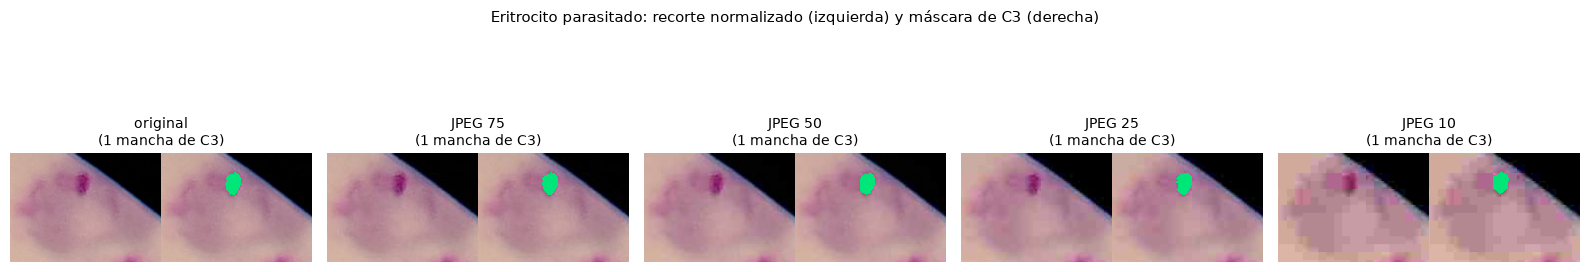

In [5]:
# Una célula parasitada de la imagen de ejemplo, con una mancha clara en el original
reg = next(r for r in cargar_subset("train") if r["image_id"] == "IMG_20150819_133447.jpg")
anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
cel_ej = celulas[(celulas["version"] == "original") & (celulas["image_id"] == reg["image_id"]) & celulas["y"]]
cell_ej = cel_ej.sort_values("area_mancha_max", ascending=False)["cell_id"].iloc[3]

mostrar = ["original", "JPEG 75", "JPEG 50", "JPEG 25", "JPEG 10"]
fig, ax = plt.subplots(1, len(mostrar), figsize=(3.2 * len(mostrar), 3.8))
for eje, nombre in zip(ax, mostrar):
    img, fondo = ejemplos[nombre]
    meta, recorte, mascara = next(c for c in eritrocitos_gt(img, anot, reg["patient_id"], reg["image_id"]) if c[0]["cell_id"] == cell_ej)
    norm = normalizar_fondo(recorte, fondo, FONDO_REF)
    manchas, _ = manchas_c3(norm[:, :, 1], mascara, **PARAMS_C3)
    pintada = norm.copy()
    pintada[manchas] = [0, 230, 120]
    eje.imshow(np.hstack([norm, pintada]))
    n = celulas.loc[(celulas["version"] == nombre) & (celulas["cell_id"] == cell_ej), "n_manchas"].iloc[0]
    eje.set_title(f"{nombre}\n({n} mancha{'s' if n != 1 else ''} de C3)", fontsize=10)
    eje.axis("off")
plt.suptitle("Eritrocito parasitado: recorte normalizado (izquierda) y máscara de C3 (derecha)", fontsize=11)
plt.tight_layout()
plt.show()

## 4. Efecto sobre las características de color

Para cada característica y cada calidad comparamos el valor de cada célula con el que tenía en la imagen original:
- **Cambio relativo:** mediana de |valor comprimido − valor original|, dividida por el **desvío de esa característica entre células** en la original. Un valor de 0.1 significa que la compresión mueve la característica un 10 % de lo que varía de una célula a otra.
- **Correlación de Spearman** con la original: si se mantiene cerca de 1, las células conservan su orden (las más "sospechosas" siguen siéndolo).
- **AUC** (parasitadas vs. sanas, `max(AUC, 1 − AUC)`): si la característica sigue **separando** las clases.

Mostramos las características más usadas en C4-C5 y el promedio de las 47.

In [6]:
CARACTERISTICAS = [c for c in celulas.columns
                   if c not in ["version", "calidad", "cell_id", "image_id", "patient_id", "label", "y", "pred", "n_pixeles"]]
CLAVE = ["n_manchas", "contraste_G_mancha", "b_rel_p1", "a_desvio", "area_cromatica", "frac_violeta", "G_hist_0", "G_media", "b_media"]

orig = celulas[celulas["version"] == "original"].set_index("cell_id")
filas = []
for nombre in VERSIONES[1:]:
    comp = celulas[celulas["version"] == nombre].set_index("cell_id").loc[orig.index]
    for c in CARACTERISTICAS:
        desvio = orig[c].std()
        auc = roc_auc_score(comp["y"], comp[c])
        filas.append({"version": nombre, "caracteristica": c,
                      "cambio relativo": (comp[c] - orig[c]).abs().median() / desvio if desvio > 0 else 0.0,
                      "Spearman": comp[c].corr(orig[c], method="spearman"),
                      "AUC": max(auc, 1 - auc)})
efecto = pd.DataFrame(filas)

auc_original = {c: max(a, 1 - a) for c in CARACTERISTICAS for a in [roc_auc_score(orig["y"], orig[c])]}
tabla = efecto[efecto["caracteristica"].isin(CLAVE)].pivot(index="caracteristica", columns="version", values="AUC")[VERSIONES[1:]]
tabla.insert(0, "original", pd.Series(auc_original))
print("AUC (parasitadas vs. sanas) de las características principales:")
print(tabla.loc[CLAVE].round(3).to_string())

print("\nPromedio de las 47 características:")
promedio = efecto.groupby("version")[["cambio relativo", "Spearman", "AUC"]].mean().reindex(VERSIONES[1:])
promedio.round(3)

AUC (parasitadas vs. sanas) de las características principales:
version             original  JPEG 95  JPEG 85  JPEG 75  JPEG 50  JPEG 25  JPEG 10
caracteristica                                                                    
n_manchas              0.984    0.984    0.984    0.984    0.984    0.985    0.982
contraste_G_mancha     0.988    0.988    0.988    0.988    0.988    0.988    0.986
b_rel_p1               0.981    0.980    0.979    0.980    0.980    0.975    0.926
a_desvio               0.982    0.981    0.981    0.980    0.979    0.975    0.901
area_cromatica         0.965    0.965    0.964    0.964    0.966    0.965    0.960
frac_violeta           0.959    0.959    0.956    0.958    0.955    0.957    0.921
G_hist_0               0.967    0.967    0.965    0.965    0.967    0.966    0.961
G_media                0.857    0.857    0.856    0.857    0.859    0.858    0.848
b_media                0.854    0.854    0.858    0.862    0.855    0.854    0.885

Promedio de las 47 car

,cambio relativo,Spearman,AUC
version,,,
JPEG 95,0.003,0.996,0.863
JPEG 85,0.006,0.988,0.865
JPEG 75,0.022,0.977,0.866
JPEG 50,0.079,0.946,0.862
JPEG 25,0.134,0.880,0.849
JPEG 10,0.668,0.723,0.849


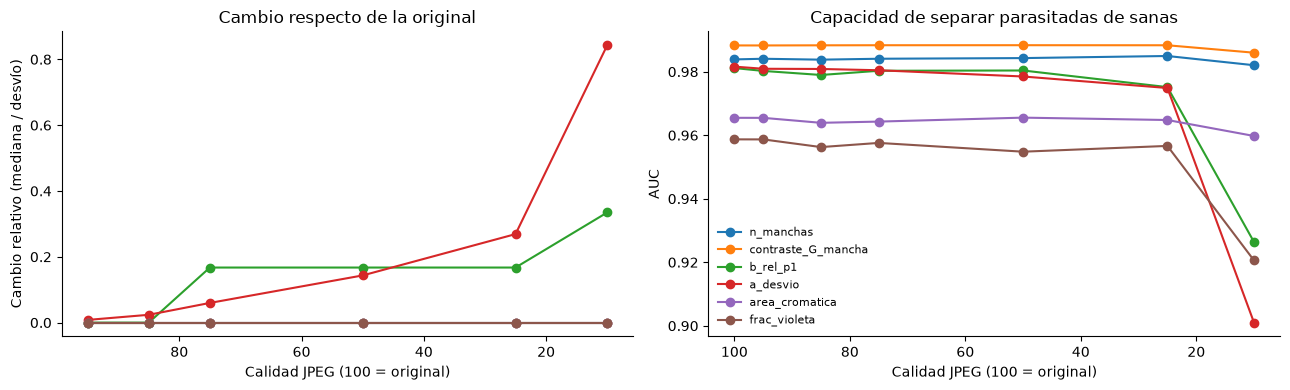

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = CALIDADES
for c in CLAVE[:6]:
    d = efecto[efecto["caracteristica"] == c].set_index("version").reindex(VERSIONES[1:])
    ax[0].plot(x, d["cambio relativo"], marker="o", label=c)
    ax[1].plot([100] + x, [auc_original[c]] + d["AUC"].tolist(), marker="o", label=c)
for eje, titulo, ylabel in [(ax[0], "Cambio respecto de la original", "Cambio relativo (mediana / desvío)"),
                            (ax[1], "Capacidad de separar parasitadas de sanas", "AUC")]:
    eje.invert_xaxis()
    eje.set_xlabel("Calidad JPEG (100 = original)")
    eje.set_ylabel(ylabel)
    eje.set_title(titulo)
    eje.spines[["top", "right"]].set_visible(False)
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

En el gráfico de la izquierda, las características de manchas (`n_manchas`, `contraste_G_mancha`), `area_cromatica` y `frac_violeta` quedan en 0 porque en la **mayoría de las células no cambian nada** (la mediana del cambio es 0): las sanas no tienen manchas ni píxeles en el rango violeta, con o sin compresión. `b_rel_p1` sube "en escalones" porque el canal b toma valores enteros: un escalón es un cambio de 1 nivel.

## 5. Efecto sobre la identificación de parasitadas (criterio de C5)

Aplicamos el criterio final de C5 (**"la célula tiene al menos una mancha de C3"**) sobre cada versión, con los parámetros fijos de train. Mostramos las métricas sobre los 6 pacientes juntos, la exactitud balanceada media por paciente, y **cuántas células cambian de decisión** respecto de la imagen original.

Como los parámetros se ajustaron con estas mismas células, los valores absolutos de la fila "original" son optimistas (son sobre los datos de ajuste). Lo que interesa acá es **la diferencia** entre cada calidad y la original.

In [8]:
def metricas(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    tp, fp = int((pred & y).sum()), int((pred & ~y).sum())
    fn, tn = int((~pred & y).sum()), int((~pred & ~y).sum())
    sens, espec = tp / (tp + fn), tn / (tn + fp)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "precisión": tp / (tp + fp) if tp + fp else np.nan,
            "sensibilidad": sens, "especificidad": espec, "F1": 2 * tp / (2 * tp + fp + fn),
            "exactitud balanceada": (sens + espec) / 2}


celulas["pred"] = celulas["n_manchas"] >= 1
pred_original = celulas[celulas["version"] == "original"].set_index("cell_id")["pred"]
filas = []
for nombre in VERSIONES:
    d = celulas[celulas["version"] == nombre]
    pp = [metricas(g["y"], g["pred"])["exactitud balanceada"] for _, g in d.groupby("patient_id")]
    cambian = (d.set_index("cell_id")["pred"] != pred_original.loc[d["cell_id"]].values).sum()
    filas.append({"version": nombre, **metricas(d["y"], d["pred"]),
                  "exactitud bal. (media por paciente)": np.mean(pp),
                  "células que cambian de decisión": int(cambian)})
identificacion = pd.DataFrame(filas).set_index("version")
identificacion.round(3)

,TP,FP,FN,TN,precisión,sensibilidad,especificidad,F1,exactitud balanceada,exactitud bal. (media por paciente),células que cambian de decisión
version,,,,,,,,,,,
original,213,40,4,2095,0.842,0.982,0.981,0.906,0.981,0.957,0
JPEG 95,213,39,4,2096,0.845,0.982,0.982,0.908,0.982,0.957,1
JPEG 85,213,41,4,2094,0.839,0.982,0.981,0.904,0.981,0.957,1
JPEG 75,213,39,4,2096,0.845,0.982,0.982,0.908,0.982,0.957,3
JPEG 50,213,38,4,2097,0.849,0.982,0.982,0.910,0.982,0.958,2
JPEG 25,213,34,4,2101,0.862,0.982,0.984,0.918,0.983,0.959,6
JPEG 10,212,36,5,2099,0.855,0.977,0.983,0.912,0.980,0.941,11


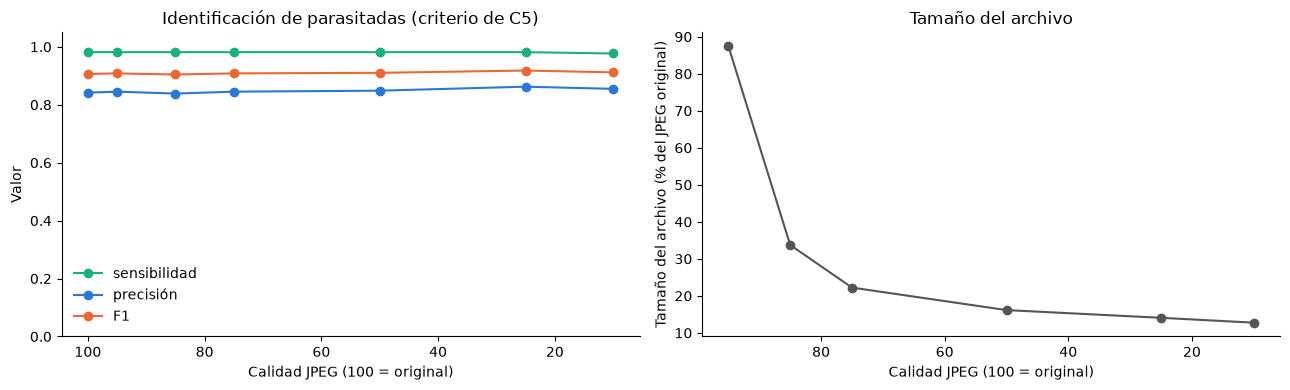

Guardado: results/c6_resultados_jpeg.csv


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
calidad_x = [100] + CALIDADES
for metrica, color in [("sensibilidad", "#1baf7a"), ("precisión", "#2a78d6"), ("F1", "#eb6834")]:
    ax[0].plot(calidad_x, identificacion[metrica].values, marker="o", label=metrica, color=color)
ax[0].set_ylim(0, 1.05)
ax[0].set_ylabel("Valor")
ax[0].set_title("Identificación de parasitadas (criterio de C5)")
ax[0].legend(frameon=False)
ax[1].plot(CALIDADES, resumen_imagen["tamaño (% del original)"].values, marker="o", color="#555555")
ax[1].set_ylabel("Tamaño del archivo (% del JPEG original)")
ax[1].set_title("Tamaño del archivo")
for eje in ax:
    eje.invert_xaxis()
    eje.set_xlabel("Calidad JPEG (100 = original)")
    eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Tabla resumen guardada para el informe
resumen = resumen_imagen.join(identificacion[["sensibilidad", "precisión", "F1", "células que cambian de decisión"]], how="outer")
resumen = resumen.reindex(VERSIONES)
resumen.to_csv(CARPETA_RESULTADOS / "c6_resultados_jpeg.csv")
print("Guardado: results/c6_resultados_jpeg.csv")

## 6. Conclusiones de C6

Todo es sobre las 12 imágenes de **train** y sus eritrocitos del GT, con los parámetros fijos de C2-C5. Lo que se compara es cada calidad JPEG contra la imagen original.

1. **El tamaño baja mucho con poca compresión:** con calidad 85 el archivo queda en el **34 %** del original, y con calidad 75 en el **22 %**. Comprimir más casi no achica el archivo (16 % con calidad 50, 13 % con calidad 10), pero sí degrada la imagen.
2. **Calidad de la imagen:** hasta calidad 50 el PSNR es mayor a 46 dB, el SSIM mayor a 0.97 y el cambio cromático **medio** dentro de los eritrocitos es inferior a **1.5 unidades ΔE76**, lo que indica una alteración promedio reducida (como referencia orientativa, ΔE ≈ 2.3 suele considerarse una diferencia apenas perceptible). Sin embargo, al ser un promedio sobre todos los píxeles de las células, **no descarta modificaciones mayores en regiones localizadas de interés**, como las manchas de los parásitos. Con calidad 25 el ΔE medio es 2.4, y con calidad 10 se duplica (4.6) y aparecen a simple vista los **bloques de 8×8** de JPEG (ver la figura).
3. **Hasta calidad 75, las características cromáticas muestran cambios relativamente pequeños** respecto de la imagen original (cambio relativo ≤ 0.022), con una correlación media de Spearman superior a 0.97. Para calidades menores, la modificación aumenta progresivamente: Spearman 0.946 con calidad 50, 0.880 con calidad 25 y 0.723 con calidad 10 (cambio relativo 0.67).
4. **Las más afectadas son las que miden variación fina del color:** `a_desvio` y `b_rel_p1` mantienen su AUC hasta calidad 25 (≈0.975), pero con calidad 10 bajan a 0.90-0.93. Tiene sentido: JPEG guarda el color con menos resolución que el brillo (submuestreo de croma) y suaviza los detalles dentro de cada bloque, así que se pierden las diferencias chicas de a y b dentro de la célula.
5. **Las características asociadas a las manchas oscuras de C3 resultaron relativamente resistentes a la compresión** (`n_manchas`, `contraste_G_mancha`: AUC ≈ 0.98-0.99 incluso con calidad 10), igual que el **área cromática** (0.96). Esto podría explicarse principalmente por el **contraste local** de estas regiones (más de 39 niveles por debajo de la mediana de la célula en G), que permite seguir detectándolas aun cuando JPEG modifica los detalles de la imagen. También puede influir que G depende sobre todo del **brillo**, que JPEG guarda con más resolución que el color, y que las manchas de parásitos suelen tener un diámetro de unos 10-30 píxeles (un área de cientos de píxeles), algo mayor que un bloque de 8×8 (64 píxeles de área). No lo verificamos de forma directa.
6. **El criterio de C5 es muy robusto a la compresión:** hasta calidad 25 detecta las mismas **213 de 217** parasitadas que en la original, y con calidad 10 pierde solo una más (212). Los falsos positivos se mantienen o bajan un poco (de 40 en la original a entre 34 y 41), probablemente porque la compresión suaviza algunos puntitos oscuros chicos. De las 2352 células, cambian de decisión como mucho 3 hasta calidad 75, 6 con calidad 25 y 11 con calidad 10. La exactitud balanceada media por paciente se mantiene en 0.957-0.959 hasta calidad 25 y baja a 0.941 con calidad 10.
7. **Recomendación:** en las imágenes analizadas, una recompresión JPEG con **calidad igual o superior a 75** permitió reducir considerablemente el tamaño de los archivos (a menos de un cuarto) sin afectar de manera apreciable las métricas de identificación. Por lo tanto, constituye una **alternativa razonable para este conjunto de datos**, aunque deberá comprobarse su efecto sobre el pipeline completo (incluida la segmentación) y en pacientes nuevos. Hasta calidad 25 la identificación se mantuvo, pero ya se degradan las características de variación de color; **calidad 10 no es recomendable**.
8. **Limitaciones:**
   - las imágenes originales **ya son JPEG**, así que esto mide el efecto de una compresión **adicional**;
   - la comparación entre calidades permite analizar la **estabilidad del método ante una recompresión adicional**. Sin embargo, como los parámetros se ajustaron con train, los resultados deben interpretarse como un **análisis de robustez sobre los datos de desarrollo** y no como una estimación definitiva de generalización (tanto los valores absolutos como la propia resistencia a la compresión podrían ser distintos en pacientes nuevos);
   - es sobre las células del GT: el efecto de la compresión sobre la **segmentación** del Bloque A (que también pide el anteproyecto) hay que evaluarlo en la integración, con `main.py`;
   - el ΔE se midió sobre todos los píxeles de los eritrocitos; una mejora posible sería medirlo solo dentro de las manchas de C3;
   - test no se usó.

**Archivo generado:** `results/c6_resultados_jpeg.csv`, con la calidad de imagen y la identificación para cada nivel de compresión.